In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [51]:
df = pd.read_csv("delhi_metro_updated.csv")
df.head()

,Date,From_Station,To_Station,Distance_km,Fare,Cost_per_passenger,Passengers,Ticket_Type,Remarks,Year,Month,Day
0,08-05-2022,Inderlok,Barakhamba Road,12.94,77.99,18.27,13.0,Smart Card,maintenance,2022,May,Sunday
1,12-01-2023,Model Town,Rajiv Chowk,2.33,35.89,83.71,15.0,Tourist Card,maintenance,2023,January,Thursday
2,13-07-2023,Kashmere Gate,New Delhi,5.56,64.35,43.70,9.0,Single,off-peak,2023,July,Thursday
3,10-11-2022,Chandni Chowk,Rajouri Garden,4.02,144.13,14.98,27.0,NaN,maintenance,2022,November,Thursday
4,06-11-2022,Rajiv Chowk,Shivaji Park,9.66,104.96,83.84,23.0,Single,off-peak,2022,November,Sunday


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                150000 non-null  object 
 1   From_Station        150000 non-null  object 
 2   To_Station          150000 non-null  object 
 3   Distance_km         150000 non-null  float64
 4   Fare                150000 non-null  float64
 5   Cost_per_passenger  150000 non-null  float64
 6   Passengers          148500 non-null  float64
 7   Ticket_Type         148500 non-null  object 
 8   Remarks             123743 non-null  object 
 9   Year                150000 non-null  int64  
 10  Month               150000 non-null  object 
 11  Day                 150000 non-null  object 
dtypes: float64(4), int64(1), object(7)
memory usage: 13.7+ MB


In [53]:
df.describe()

,Distance_km,Fare,Cost_per_passenger,Passengers,Year
count,150000.000000,150000.000000,150000.000000,148500.000000,150000.000000
mean,5.490446,105.116503,62.474807,20.003522,2023.000580
std,4.980333,54.879494,33.207161,4.468134,0.816397
min,0.500000,10.000000,5.000000,4.000000,2022.000000
25%,1.940000,57.570000,33.687500,17.000000,2022.000000
50%,3.960000,105.170000,62.520000,20.000000,2023.000000
75%,7.420000,152.572500,91.190000,23.000000,2024.000000
max,63.030000,200.000000,120.000000,41.000000,2024.000000


In [54]:
df.isnull().sum()

,0
Date,0
From_Station,0
To_Station,0
Distance_km,0
Fare,0
Cost_per_passenger,0
Passengers,1500
Ticket_Type,1500
Remarks,26257
Year,0


In [55]:
df = df.drop(['Date'], axis=1)
df.head(5)

,From_Station,To_Station,Distance_km,Fare,Cost_per_passenger,Passengers,Ticket_Type,Remarks,Year,Month,Day
0,Inderlok,Barakhamba Road,12.94,77.99,18.27,13.0,Smart Card,maintenance,2022,May,Sunday
1,Model Town,Rajiv Chowk,2.33,35.89,83.71,15.0,Tourist Card,maintenance,2023,January,Thursday
2,Kashmere Gate,New Delhi,5.56,64.35,43.70,9.0,Single,off-peak,2023,July,Thursday
3,Chandni Chowk,Rajouri Garden,4.02,144.13,14.98,27.0,NaN,maintenance,2022,November,Thursday
4,Rajiv Chowk,Shivaji Park,9.66,104.96,83.84,23.0,Single,off-peak,2022,November,Sunday


In [56]:
df.Passengers = df.Passengers.fillna(df.Passengers.mean())

In [57]:
df.isnull().sum()

,0
From_Station,0
To_Station,0
Distance_km,0
Fare,0
Cost_per_passenger,0
Passengers,0
Ticket_Type,1500
Remarks,26257
Year,0
Month,0


In [58]:
df.Ticket_Type = df.Ticket_Type.fillna(df.Ticket_Type.mode()[0])
df.Remarks = df.Remarks.fillna(df.Remarks.mode()[0])

In [59]:
df.isnull().sum()

,0
From_Station,0
To_Station,0
Distance_km,0
Fare,0
Cost_per_passenger,0
Passengers,0
Ticket_Type,0
Remarks,0
Year,0
Month,0


In [60]:
df.head(5)

,From_Station,To_Station,Distance_km,Fare,Cost_per_passenger,Passengers,Ticket_Type,Remarks,Year,Month,Day
0,Inderlok,Barakhamba Road,12.94,77.99,18.27,13.0,Smart Card,maintenance,2022,May,Sunday
1,Model Town,Rajiv Chowk,2.33,35.89,83.71,15.0,Tourist Card,maintenance,2023,January,Thursday
2,Kashmere Gate,New Delhi,5.56,64.35,43.70,9.0,Single,off-peak,2023,July,Thursday
3,Chandni Chowk,Rajouri Garden,4.02,144.13,14.98,27.0,Tourist Card,maintenance,2022,November,Thursday
4,Rajiv Chowk,Shivaji Park,9.66,104.96,83.84,23.0,Single,off-peak,2022,November,Sunday


In [61]:
df['Ticket_Type'].value_counts()

,count
Ticket_Type,
Tourist Card,60693
Single,37341
Smart Card,37244
Return,14722


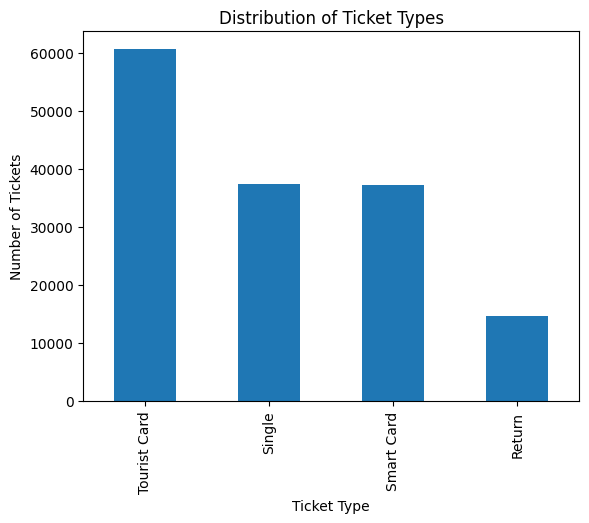

In [62]:
df['Ticket_Type'].value_counts().plot(kind='bar')
plt.title('Distribution of Ticket Types')
plt.xlabel('Ticket Type')
plt.ylabel('Number of Tickets')
plt.show()

In [63]:
df.groupby('Day')['Passengers'].sum().sort_values(ascending=False)

,Passengers
Day,
Saturday,434829.736074
Tuesday,433327.764249
Sunday,430735.792424
Wednesday,428201.721987
Monday,427310.827643
Thursday,423505.725508
Friday,422616.714943


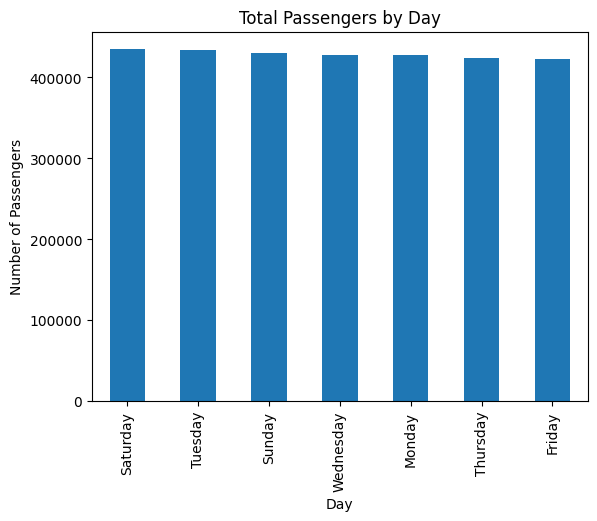

In [64]:
df.groupby('Day')['Passengers'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Total Passengers by Day')
plt.xlabel('Day')
plt.ylabel('Number of Passengers')
plt.show()

In [65]:
df.groupby('Month')['Passengers'].sum().sort_values(ascending=False)

,Passengers
Month,
August,258878.422626
July,257632.478976
January,254038.408539
March,253940.443758
December,253745.397973
May,252393.450801
October,252226.440236
June,248980.450801
April,248746.461367


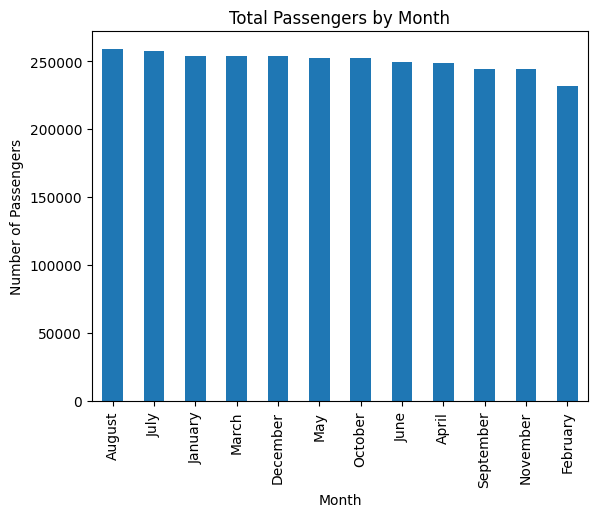

In [66]:
df.groupby('Month')['Passengers'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Total Passengers by Month')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')
plt.show()

In [67]:
df.groupby('Year')['Passengers'].sum().sort_values(ascending=False)

,Passengers
Year,
2024,1.001813e+06
2023,1.000749e+06
2022,9.979668e+05


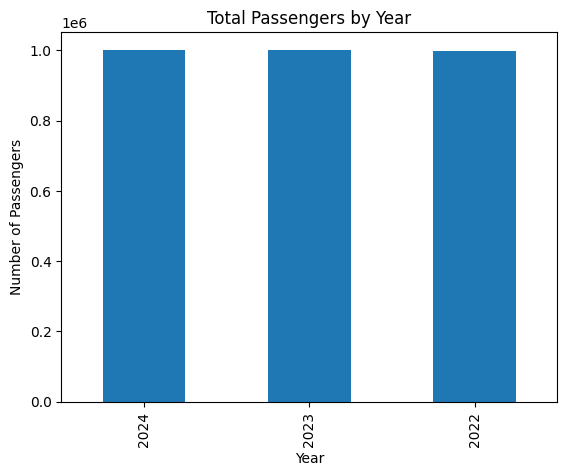

In [68]:
df.groupby('Year')['Passengers'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Total Passengers by Year')
plt.xlabel('Year')
plt.ylabel('Number of Passengers')
plt.show()

In [69]:
df.Fare.describe()

,Fare
count,150000.000000
mean,105.116503
std,54.879494
min,10.000000
25%,57.570000
50%,105.170000
75%,152.572500
max,200.000000


In [70]:
df['From_Station'].value_counts().head(10)

,count
From_Station,
Rajiv Chowk,15593
Noida City Centre,12049
New Delhi,8173
Mandi House,8044
Dilshad Garden,4461
Chandni Chowk,4420
Kalkaji Mandir,4417
Central Secretariat,4413
Janakpuri West,4412


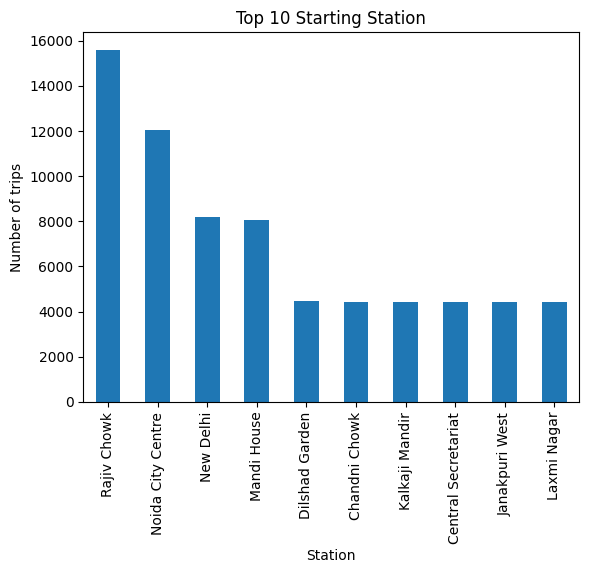

In [71]:
df.From_Station.value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Starting Station')
plt.xlabel('Station')
plt.ylabel('Number of trips')
plt.show()

In [73]:
df.To_Station.value_counts().head(10)

,count
To_Station,
Kirti Nagar,6370
Hauz Khas,6370
Janakpuri West,6339
Noida City Centre,6338
Old Delhi,6313
Netaji Subhash Place,6310
Dilshad Garden,6305
Kashmere Gate,6294
Pragati Maidan,6282


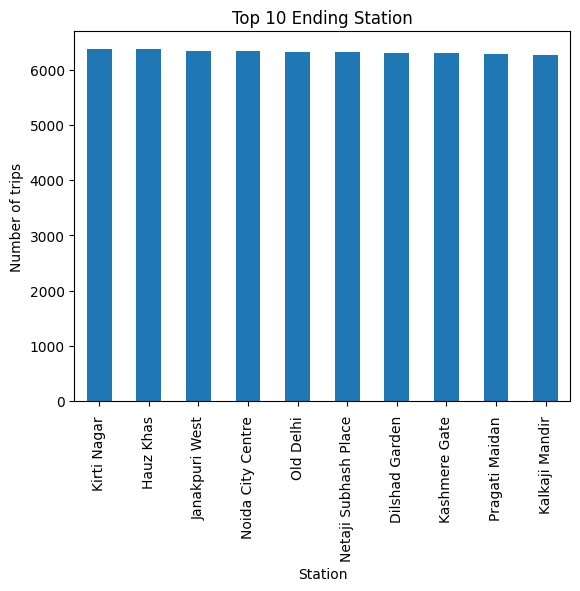

In [72]:
df.To_Station.value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Ending Station')
plt.xlabel('Station')
plt.ylabel('Number of trips')
plt.show()

In [74]:
df['Remarks'].value_counts()

,count
Remarks,
off-peak,51116
festival,24812
maintenance,24771
weekend,24710
peak,24591


In [75]:
df.groupby('Remarks')['Passengers'].sum().sort_values(ascending=False)

,Passengers
Remarks,
off-peak,1.023184e+06
festival,4.957739e+05
maintenance,4.957669e+05
weekend,4.942909e+05
peak,4.915129e+05


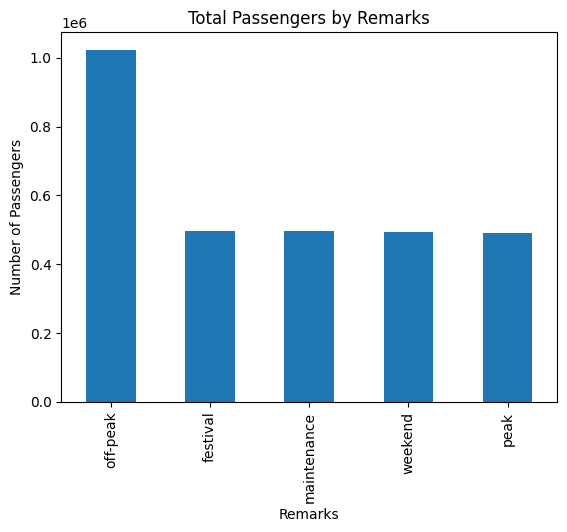

In [76]:
df.groupby('Remarks')['Passengers'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Total Passengers by Remarks')
plt.xlabel('Remarks')
plt.ylabel('Number of Passengers')
plt.show()

In [78]:
df.nlargest(10, 'Fare')[['From_Station','To_Station','Distance_km','Fare','Passengers']]

,From_Station,To_Station,Distance_km,Fare,Passengers
39639,mandi house,Janakpuri West,2.59,200.00,22.0
58707,Noida City Centre,New Delhi,9.38,200.00,19.0
70170,AIIMS,Shivaji Park,3.09,200.00,16.0
2897,Kashmere Gate,Central Secretariat,14.66,199.99,15.0
16825,Rajouri Garden,AIIMS,0.75,199.99,29.0
75716,Central Secretariat,Jasola Vihar,2.87,199.99,24.0
78544,Rajiv Chowk,Model Town,1.01,199.99,21.0
78826,Mandi House,Shivaji Park,2.75,199.99,19.0
93572,Chandni Chowk,Kashmere Gate,1.24,199.99,17.0
126730,Barakhamba Road,Inderlok,5.36,199.99,25.0


In [79]:
df.to_csv('Delhi_metro(jupter_notebook).csv', index=False)